# Chương 5 bài 2 SVM dữ liệu động vật

**Nguồn:** Lab phân lớp, mục 2.2.4, trang 13

**Đề bài:** Xây dựng mô hình SVM trên dữ liệu các con thú trong rừng.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C5_BT02_SVM_DongVat'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Kiểm tra nhãn và dữ liệu

In [2]:
raw = pd.read_csv(DATA / 'data_2_2_4.csv')
print('Raw:', raw.shape)
print('Labels:', raw.Dangerous.value_counts(dropna=False).to_dict())
# Remove missing target before duplicate checking.
df = raw.dropna(subset=['Dangerous']).copy()
df['Dangerous'] = df['Dangerous'].str.strip()
conflicts = df.groupby(list(df.columns[:-1]), dropna=False)['Dangerous'].nunique()
print('Feature profiles with conflicting labels:', int((conflicts > 1).sum()))
# Keep unique complete records; avoid identical train/test rows.
before = len(df)
df = df.drop_duplicates()
print('Duplicate rows removed:', before-len(df))
if not set(df.Dangerous.unique()).issubset({'Yes','No'}):
    raise ValueError('Unexpected target label')
X = df.drop(columns='Dangerous')
y = df['Dangerous'].map({'No':0, 'Yes':1})
print('Labels after cleaning:', y.value_counts().to_dict())

Raw: (871, 7)
Labels: {'Yes': 849, 'No': 20, nan: 2}
Feature profiles with conflicting labels: 0
Duplicate rows removed: 28
Labels after cleaning: {1: 821, 0: 20}


## 2 Chia dữ liệu có phân tầng

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Test classes:', y_test.value_counts().to_dict())

Train: (672, 6) Test: (169, 6)
Test classes: {1: 165, 0: 4}


## 3 Mã hóa đặc trưng từ train

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
fill = SimpleImputer(strategy='most_frequent')
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_filled = fill.fit_transform(X_train)
X_test_filled = fill.transform(X_test)
X_train_ready = encoder.fit_transform(X_train_filled)
X_test_ready = encoder.transform(X_test_filled)
print('Encoded feature count:', X_train_ready.shape[1])

Encoded feature count: 1112


## 4 Huấn luyện SVM

In [5]:
from sklearn.svm import SVC
# Fixed parameters, not a claim of optimal tuning.
model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True,
            random_state=42, class_weight='balanced')
model.fit(X_train_ready, y_train)

SVC(class_weight='balanced', probability=True, random_state=42)


## 5 Đánh giá

accuracy             1.0
precision            1.0
recall               1.0
f1                   1.0
roc_auc              1.0
recall_negative      1.0
balanced_accuracy    1.0
average_precision    1.0
dtype: float64
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00       165

    accuracy                           1.00       169
   macro avg       1.00      1.00      1.00       169
weighted avg       1.00      1.00      1.00       169



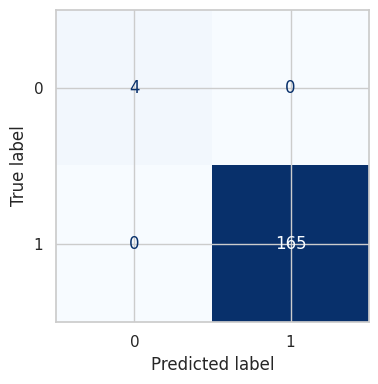

In [6]:
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)
pred = model.predict(X_test_ready)
prob = model.predict_proba(X_test_ready)[:, list(model.classes_).index(1)]
metrics = {'accuracy':float(accuracy_score(y_test,pred)),
           'precision':float(precision_score(y_test,pred,zero_division=0)),
           'recall':float(recall_score(y_test,pred,zero_division=0)),
           'f1':float(f1_score(y_test,pred,zero_division=0)),
           'roc_auc':float(roc_auc_score(y_test,prob)),
           'recall_negative':float(recall_score(y_test,pred,pos_label=0,zero_division=0)),
                 'balanced_accuracy':float(balanced_accuracy_score(y_test,pred)),
                 'average_precision':float(average_precision_score(y_test,prob))}
print(pd.Series(metrics).round(4))
print(classification_report(y_test,pred,zero_division=0))
pd.DataFrame([metrics]).to_csv(OUT / 'metrics.csv',index=False)
ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues',colorbar=False)
save_fig('01_confusion_matrix.png')
save_summary({'train_rows':len(y_train),'test_rows':len(y_test),
              'positive_label':1, 'metrics':metrics})

## Nhận xét và giới hạn
Bộ dữ liệu này dự đoán Dangerous (Yes/No) theo loài và triệu chứng, không phải nhận diện loài từ ảnh. Dữ liệu rất mất cân bằng; cần đọc confusion matrix và recall của từng lớp. Các hồ sơ triệu chứng mâu thuẫn được báo số lượng; không tự sửa nhãn. One-hot giữ đầu vào 0/1 nên không cần chuẩn hóa lại như biến số đo liên tục.